# Chapitre 2 - Exercices 2.6 à 2.10

Ce notebook traite les exercices 2.6 à 2.10, centrés sur les langages de requête :

- **2.6** : un rapport en pipeline d'agrégation et en SQL (mini-lab) ;
- **2.7** : une généalogie en SQL récursif, et une erreur de saisie qui crée un cycle
  (mini-lab) ;
- **2.8** : une même question en Cypher, SPARQL, Datalog et SQL (mini-lab) ;
- **2.9** : récursion linéaire ou non linéaire en Datalog : tours contre dérivations
  (calcul et mesure) ;
- **2.10** : estimer la sélectivité pour ordonner les motifs d'une requête de
  triplets (calcul).

In [1]:
import itertools
import math
import sqlite3
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 2.6 : un rapport en pipeline d'agrégation et en SQL

**Énoncé.** On reprend les observations d'animaux marins (`dm.make_observations`), et une
collection `observers` (identifiant, nom, club de plongée).

1. Écrire un pipeline d'agrégation qui donne, pour chaque famille et chaque mois d'**été**
   (juin, juillet, août) : le nombre d'observations, le total d'animaux et la taille
   moyenne des groupes, triés par famille puis par mois.
2. Écrire un second pipeline qui donne, pour les requins, le total d'animaux observés par
   **club** (il faut une jointure `$lookup` vers `observers`).
3. Écrire les deux requêtes en SQL sur SQLite et vérifier que les résultats sont égaux.
4. Quel est le rôle de l'étape `$project` dans le pipeline 1 ? Que faudrait-il pour que
   la base exploite un index dans le pipeline 2 ?

**Rappels.** Étapes `$match`, `$project`, `$group`, `$sort`, `$lookup`, `$unwind` ; le
pipeline équivaut à un sous-ensemble de SQL (cours 3, section *MapReduce Querying*).

**Solution.** Les pipelines et les requêtes SQL sont ci-dessous. *4.* `$project` calcule
le mois à partir de l'horodatage pour pouvoir **filtrer dessus** ensuite : notre `$match`
ne compare que des champs. Pour le pipeline 2, placer le `$match` sur `family` **en
premier** permet d'utiliser un index sur ce champ et de ne faire la jointure que sur les
requins ; un index sur `observers._id` (la clé primaire) sert la jointure.

In [2]:
obs = dm.make_observations(20_000, seed=2)
clubs = ["Les Mérous", "Bulles d'Iroise", "Club Calanques", "Nautilus"]
observers = [{"_id": i, "nom": f"plongeur {i}", "club": clubs[i % 4]} for i in range(1, 40)]

PIPE1 = [
    {"$project": {"family": 1, "numAnimals": 1, "mois": {"$month": "$observationTimestamp"}}},
    {"$match": {"mois": {"$in": [6, 7, 8]}}},
    {"$group": {"_id": {"family": "$family", "mois": "$mois"},
                "n": {"$sum": 1}, "total": {"$sum": "$numAnimals"}, "moyenne": {"$avg": "$numAnimals"}}},
    {"$sort": {"_id.family": 1, "_id.mois": 1}},
]
PIPE2 = [
    {"$match": {"family": "Sharks"}},
    {"$lookup": {"from": "observers", "localField": "observer_id", "foreignField": "_id", "as": "obs"}},
    {"$unwind": "$obs"},
    {"$group": {"_id": "$obs.club", "total": {"$sum": "$numAnimals"}}},
    {"$sort": {"total": -1}},
]
r1 = dm.aggregate(obs, PIPE1)
r2 = dm.aggregate(obs, PIPE2, collections={"observers": observers})

con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE observations (id INTEGER PRIMARY KEY, ts TEXT, family TEXT, num INTEGER, observer_id INTEGER)")
con.executemany("INSERT INTO observations VALUES (?, ?, ?, ?, ?)",
                [(o["_id"], o["observationTimestamp"], o["family"], o["numAnimals"], o["observer_id"]) for o in obs])
con.execute("CREATE TABLE observers (id INTEGER PRIMARY KEY, nom TEXT, club TEXT)")
con.executemany("INSERT INTO observers VALUES (?, ?, ?)", [(o["_id"], o["nom"], o["club"]) for o in observers])
SQL1 = """SELECT family, CAST(strftime('%m', ts) AS INTEGER) AS mois, COUNT(*), SUM(num), AVG(num)
            FROM observations WHERE CAST(strftime('%m', ts) AS INTEGER) IN (6, 7, 8)
           GROUP BY family, mois ORDER BY family, mois"""
SQL2 = """SELECT o.club, SUM(x.num) AS total FROM observations x JOIN observers o ON o.id = x.observer_id
           WHERE x.family = 'Sharks' GROUP BY o.club ORDER BY total DESC"""
s1, s2 = con.execute(SQL1).fetchall(), con.execute(SQL2).fetchall()
assert [(r["_id"]["family"], r["_id"]["mois"], r["n"], r["total"]) for r in r1] == [t[:4] for t in s1]
assert np.allclose([r["moyenne"] for r in r1], [t[4] for t in s1])
assert [(r["_id"], r["total"]) for r in r2] == s2
print("pipelines et SQL : résultats identiques")
pd.DataFrame([{"famille": r["_id"]["family"], "mois": r["_id"]["mois"], "observations": r["n"],
               "animaux": r["total"], "taille moyenne": r["moyenne"]} for r in r1]).head(6)

pipelines et SQL : résultats identiques


,famille,mois,observations,animaux,taille moyenne
0,Cetaceans,6,605,1423,2.352
1,Cetaceans,7,610,1328,2.177
2,Cetaceans,8,588,1270,2.160
3,Rays,6,215,432,2.009
4,Rays,7,270,624,2.311
5,Rays,8,268,613,2.287


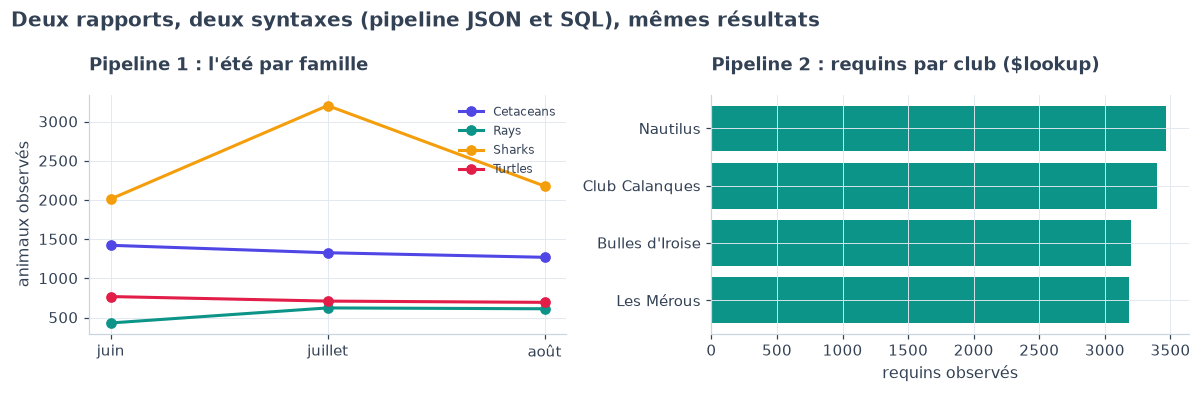

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
t1 = pd.DataFrame([{"famille": r["_id"]["family"], "mois": r["_id"]["mois"], "animaux": r["total"]} for r in r1])
for (fam, sub), col in zip(t1.groupby("famille"), COLORS):
    axes[0].plot(sub["mois"], sub["animaux"], marker="o", color=col, label=fam)
axes[0].set_xticks([6, 7, 8], ["juin", "juillet", "août"]); axes[0].set_ylabel("animaux observés")
axes[0].set_title("Pipeline 1 : l'été par famille"); axes[0].legend(fontsize=8)
axes[1].barh([r["_id"] for r in r2][::-1], [r["total"] for r in r2][::-1], color=TEAL)
axes[1].set_xlabel("requins observés"); axes[1].set_title("Pipeline 2 : requins par club ($lookup)")
finish(fig, "Deux rapports, deux syntaxes (pipeline JSON et SQL), mêmes résultats")

Le pic estival des requins (la saison est simulée dans les données) ressort du premier
rapport. Les deux langages ont exprimé exactement les mêmes calculs : filtre, champ
calculé, regroupement, jointure, tri.

> **À retenir.** Un pipeline d'agrégation se traduit étape par étape en SQL : `$match` =
> `WHERE`, `$project` = expressions du `SELECT`, `$group` = `GROUP BY`, `$lookup` =
> `JOIN`, `$sort` = `ORDER BY`. Filtrer tôt sert les index et réduit la jointure.

## Exercice 2.7 : une généalogie en SQL récursif

**Énoncé.** Une table `parent(child, parent)` décrit un arbre généalogique de six
générations.

1. Écrire une requête `WITH RECURSIVE` qui liste tous les ancêtres d'une personne avec
   leur **génération** (1 = parents, 2 = grands-parents...).
2. Écrire une requête qui trouve l'**ancêtre commun le plus proche** de deux personnes.
3. Une erreur de saisie déclare une personne parente de son propre arrière-grand-parent.
   Que devient la requête 1 avec `UNION ALL` ? Avec `UNION` ? Écrire une requête qui
   **détecte** le cycle en mémorisant le chemin parcouru.
4. Vérifier tous les résultats par un parcours en largeur en Python.

**Rappels.** `WITH RECURSIVE` : une partie initiale, une partie récursive jointe aux
lignes du tour précédent ; `UNION` élimine les doublons, `UNION ALL` non (cours 4,
section *Graph Queries in SQL*).

**Solution.** *1.* On part des parents directs (génération 1), puis on joint récursivement
`parent` sur les ancêtres trouvés, en ajoutant 1 à la génération. *2.* On calcule les
ancêtres (avec génération) des deux personnes, on les joint, et on garde le minimum de la
somme des générations. *3.* Avec un cycle, `UNION ALL` boucle indéfiniment (chaque tour
produit une ligne nouvelle, la génération augmentant) ; `UNION` ne l'arrête pas non plus
**si la génération fait partie de la ligne**, car (ancêtre, génération) est toujours
nouveau ! Il faut soit retirer la génération (et perdre l'information), soit borner la
profondeur, soit mémoriser le chemin et refuser de revisiter un sommet.

In [4]:
gen = sqlite3.connect(":memory:")
gen.execute("CREATE TABLE parent (child INTEGER, parent INTEGER)")
pairs, next_id, generation = [], 1, [0]
for g_ in range(6):                                  # chaque personne a deux parents, plus anciens
    new = []
    for c in generation:
        for _ in range(2):
            pairs.append((c, next_id)); new.append(next_id); next_id += 1
    generation = new
cousin_a, cousin_b = 0, None
# un cousin : un autre descendant des grands-parents de 0
pairs.append((10_000, 3)); pairs.append((10_000, 9_999))           # 10 000 a pour parent la personne 3
gen.executemany("INSERT INTO parent VALUES (?, ?)", pairs)
gen.execute("CREATE INDEX parent_child ON parent (child)")

ANCETRES = """WITH RECURSIVE anc(id, g) AS (
                  SELECT parent, 1 FROM parent WHERE child = :x
                UNION
                  SELECT p.parent, anc.g + 1 FROM parent p JOIN anc ON p.child = anc.id)
              SELECT id, g FROM anc"""
PROCHE = f"""WITH RECURSIVE
               a(id, g) AS (SELECT :x, 0 UNION SELECT p.parent, a.g + 1 FROM parent p JOIN a ON p.child = a.id),
               b(id, g) AS (SELECT :y, 0 UNION SELECT p.parent, b.g + 1 FROM parent p JOIN b ON p.child = b.id)
             SELECT a.id, a.g, b.g FROM a JOIN b USING (id) ORDER BY a.g + b.g LIMIT 1"""

def bfs_ancestors(pairs, x):
    up = defaultdict(list)
    for c, p in pairs:
        up[c].append(p)
    res, front, gg = {}, [x], 0
    while front:
        gg += 1
        nxt = []
        for v in front:
            for p in up[v]:
                if p not in res:
                    res[p] = gg; nxt.append(p)
        front = nxt
    return res

anc0 = dict(gen.execute(ANCETRES, {"x": 0}).fetchall())
assert anc0 == bfs_ancestors(pairs, 0)
print(f"ancêtres de 0 : {len(anc0)} sur 6 générations ; par génération :", dict(sorted(Counter(anc0.values()).items())))
print("ancêtre commun le plus proche de 0 et 10 000 :", gen.execute(PROCHE, {"x": 0, "y": 10_000}).fetchone(),
      "(id, distance depuis 0, distance depuis 10 000)")

ancêtres de 0 : 126 sur 6 générations ; par génération : {1: 2, 2: 4, 3: 8, 4: 16, 5: 32, 6: 64}
ancêtre commun le plus proche de 0 et 10 000 : (3, 2, 1) (id, distance depuis 0, distance depuis 10 000)


Introduisons maintenant l'erreur : la personne 0 est déclarée parente de son
arrière-grand-parent 7, ce qui crée un cycle 0 -> 1 -> 3 -> 7 -> 0. On exécute la requête
1 avec une borne de génération pour éviter la boucle infinie, et la version qui mémorise
le chemin.

In [5]:
gen.execute("INSERT INTO parent VALUES (7, 0)")
borne = []
for lim in [10, 20, 40]:
    borne.append(gen.execute(f"""WITH RECURSIVE anc(id, g) AS (
                  SELECT parent, 1 FROM parent WHERE child = 0
                UNION SELECT p.parent, anc.g + 1 FROM parent p JOIN anc ON p.child = anc.id WHERE anc.g < {lim})
              SELECT COUNT(*) FROM anc""").fetchone()[0])
CYCLE = """WITH RECURSIVE walk(id, chemin, cycle) AS (
               SELECT parent, ',' || child || ',' || parent || ',', parent = child FROM parent WHERE child = 0
             UNION ALL
               SELECT p.parent, walk.chemin || p.parent || ',', instr(walk.chemin, ',' || p.parent || ',') > 0
                 FROM parent p JOIN walk ON p.child = walk.id
                WHERE NOT walk.cycle)
           SELECT chemin FROM walk WHERE cycle"""
cycles = gen.execute(CYCLE).fetchall()
print("UNION avec génération, borné à 10, 20, 40 générations :", borne, "lignes (croît avec la borne : la récursion ne s'arrête pas seule)")
print("cycle détecté par mémorisation du chemin :", cycles)

UNION avec génération, borné à 10, 20, 40 générations : [260, 539, 1174] lignes (croît avec la borne : la récursion ne s'arrête pas seule)
cycle détecté par mémorisation du chemin : [(',0,1,3,7,0,',)]


Le nombre de lignes croît avec la borne : avec la génération dans la ligne, `UNION` ne
voit jamais de doublon et la récursion ne s'arrête qu'à la borne. La requête qui
mémorise le chemin trouve exactement le cycle `0 -> 1 -> 3 -> 7 -> 0` et s'arrête. (La
norme SQL et PostgreSQL proposent pour cela une clause `CYCLE` ; voir le lab.)

> **À retenir.** `WITH RECURSIVE` exprime ancêtres et ancêtres communs en quelques lignes.
> Sur des données qui peuvent contenir des cycles, `UNION` ne suffit pas dès qu'une
> colonne (profondeur, chemin) rend chaque ligne unique : il faut une borne ou une
> détection explicite du cycle.

## Exercice 2.8 : une même question en quatre langages

**Énoncé.** Sur le graphe synthétique de lieux et de personnes (`dm.make_world_graph`),
on cherche les personnes qui **vivent sur le continent où elles sont nées**.

1. Écrire la requête en Cypher (sur papier).
2. L'écrire en motifs SPARQL et l'exécuter avec `TripleStore.query`.
3. L'écrire en Datalog et l'exécuter avec `dm.Datalog`.
4. L'écrire en SQL avec `WITH RECURSIVE` et l'exécuter sur SQLite.
5. Vérifier que les quatre résultats (avec un calcul direct en Python) coïncident, et
   comparer la longueur des requêtes.

**Rappels.** Chemins de longueur variable : `-[:WITHIN*0..]->` (Cypher), `:within*`
(SPARQL), règle récursive (Datalog), CTE récursive (SQL) (cours 4 et 5).

**Solution.** La difficulté commune est que la **même variable** (le continent) doit
apparaître dans les deux chemins : c'est une jointure sur le continent.

```cypher
MATCH (p:Person) -[:BORN_IN]->  () -[:WITHIN*0..]-> (c:Location {type: 'continent'}),
      (p)        -[:LIVES_IN]-> () -[:WITHIN*0..]-> (c)
RETURN p.name
```

En SPARQL : `?p :bornIn/:within* ?c. ?c :type "continent". ?p :livesIn/:within* ?c.`
En Datalog, on définit d'abord l'ancêtre réflexif-transitif `dans(L, C)`. En SQL, une CTE
récursive calcule toutes les paires (lieu, ancêtre), puis deux jointures.

In [6]:
w = dm.make_world_graph(n_people=3000, seed=4, countries_per_continent=4, regions_per_country=4, cities_per_region=5)
# Python direct
def continent(v):
    for a in w.closure([v], "WITHIN", "out"):
        if w.props(a).get("type") == "continent":
            return a
direct = {p["name"] for v, (lab, p) in w.vertices.items()
          if lab == "Person" and continent(w.out(v, "BORN_IN")[0]) == continent(w.out(v, "LIVES_IN")[0])}
# SPARQL (motifs)
ts = dm.graph_to_triples(w)
q_sparql = [("?c", "type", "continent"), ("?p", ("bornIn", "within*"), "?c"),
            ("?p", ("livesIn", "within*"), "?c"), ("?p", "name", "?n")]
sparql = {s["?n"] for s in ts.query(q_sparql)}
# Datalog
DL = """
dans(L, L) :- location(L, _, _).
dans(L, C) :- within(L, V), dans(V, C).
meme_continent(N) :- person(I, N), born_in(I, X), dans(X, C), location(C, _, "continent"),
                     lives_in(I, Y), dans(Y, C).
"""
ids = {v: i for i, v in enumerate(w.vertices)}
dl = dm.Datalog()
for v, (lab, p) in w.vertices.items():
    if lab == "Location":
        dl.add_fact("location", ids[v], p["name"], p["type"])
    else:
        dl.add_fact("person", ids[v], p["name"])
for _, t, h, lab, _p in w.edges:
    dl.add_fact(lab.lower(), ids[t], ids[h])
dl.add_rule(DL); dl.evaluate()
datalog = {n for (n,) in dl.query("meme_continent")}
# SQL
con = sqlite3.connect(":memory:"); w.to_sqlite(con)
SQL = """
WITH RECURSIVE dans(lieu, anc) AS (
    SELECT vertex_id, vertex_id FROM vertices WHERE label = 'Location'
  UNION
    SELECT dans.lieu, e.head_vertex FROM dans JOIN edges e ON e.tail_vertex = dans.anc AND e.label = 'WITHIN'
),
continent_de(lieu, cont) AS (
    SELECT dans.lieu, dans.anc FROM dans JOIN vertices v ON v.vertex_id = dans.anc
     WHERE v.properties ->> 'type' = 'continent'
)
SELECT p.properties ->> 'name'
  FROM vertices p
  JOIN edges b ON b.tail_vertex = p.vertex_id AND b.label = 'BORN_IN'
  JOIN edges l ON l.tail_vertex = p.vertex_id AND l.label = 'LIVES_IN'
  JOIN continent_de cb ON cb.lieu = b.head_vertex
  JOIN continent_de cl ON cl.lieu = l.head_vertex
 WHERE cb.cont = cl.cont"""
sql = {r[0] for r in con.execute(SQL)}
assert direct == sparql == datalog == sql
longueurs = {"Cypher": 3, "SPARQL (motifs)": len(q_sparql), "Datalog": len([l for l in DL.strip().splitlines() if l.strip()]),
             "SQL": len([l for l in SQL.strip().splitlines() if l.strip()])}
print(f"{len(direct)} personnes sur {sum(1 for _, (lab, _p) in w.vertices.items() if lab == 'Person')} "
      f"vivent sur leur continent de naissance : résultats identiques dans les quatre langages")
pd.DataFrame({"langage": list(longueurs), "lignes": list(longueurs.values())})

2332 personnes sur 3000 vivent sur leur continent de naissance : résultats identiques dans les quatre langages


,langage,lignes
0,Cypher,3
1,SPARQL (motifs),4
2,Datalog,4
3,SQL,16


Les quatre langages s'accordent (environ 77 % des personnes, cohérent avec le générateur :
70 % restent sur leur continent, et une partie de ceux qui partent tirent à nouveau le
même continent). Cypher et SPARQL tiennent en trois ou quatre lignes, Datalog en quatre
règles courtes, SQL en seize lignes denses.

> **À retenir.** Une variable partagée entre deux chemins (le continent) est une jointure
> dans tous les langages ; les langages de graphe l'expriment par la simple réutilisation
> d'un nom, SQL par une CTE récursive et deux jointures explicites.

## Exercice 2.9 : récursion linéaire ou non linéaire en Datalog

**Énoncé.** Sur une chaîne de $n$ arêtes, on compare trois programmes pour la fermeture
transitive :

- linéaire à droite : `path(X, Z) :- edge(X, Y), path(Y, Z).`
- linéaire à gauche : `path(X, Z) :- path(X, Y), edge(Y, Z).`
- non linéaire : `path(X, Z) :- path(X, Y), path(Y, Z).`

(chacun avec `path(X, Y) :- edge(X, Y).`)

1. Combien de tours d'évaluation faut-il pour chaque programme ? Le démontrer.
2. En évaluation semi-naïve, combien de dérivations pour les programmes linéaires ?
   Pourquoi le non linéaire en fait-il davantage ?
3. Dans un moteur distribué où chaque tour est une étape synchronisée coûteuse, lequel
   préférer ?

**Rappels.** Évaluation ascendante jusqu'au point fixe, semi-naïve avec le delta du tour
précédent (cours 5, section *The Foundation: Datalog*).

**Solution.**

*1.* **Linéaire** : par récurrence, après le tour $k$ on connaît exactement les chemins de
longueur $\le k$ (le tour $k+1$ prolonge d'une arête les chemins de longueur $k$). Le plus
long chemin ayant $n$ arêtes, il faut $n$ tours, plus un tour qui ne produit rien et
constate le point fixe : **n + 1 tours**. **Non linéaire** : après le tour $k$ on connaît
les chemins de longueur $\le 2^{k-1}$ (on concatène deux chemins connus) : il faut
$\lceil \log_2 n \rceil + 1$ tours productifs, plus le tour final, soit environ
$\log_2 n + 2$.

*2.* Linéaire semi-naïf : chaque chemin $(i, j)$ n'est dérivé qu'une fois, au tour où il
devient connu, par l'unique façon de le prolonger : $n(n+1)/2$ dérivations. Non linéaire :
un chemin de longueur $L$ peut se couper en deux chemins connus de $L - 1$ façons ; le
semi-naïf en évite une partie (au moins un morceau doit être nouveau) mais il reste de
nombreuses dérivations redondantes, de l'ordre de $n^3$.

*3.* Le non linéaire : $\log_2 n$ tours au lieu de $n$, si le surcroît de calcul par tour
reste acceptable. C'est le principe du « doublement » utilisé par les moteurs distribués.

tours                                      dérivations  \
programme linéaire à droite linéaire à gauche non linéaire linéaire à droite   
n                                                                              
8                         9                 9            5                36   
16                       17                17            6               136   
32                       33                33            7               528   
64                       65                65            8              2080   
128                     129               129            9              8256   

                                          
programme linéaire à gauche non linéaire  
n                                         
8                        36          112  
16                      136          828  
32                      528         6484  
64                     2080        51588  
128                    8256       412132

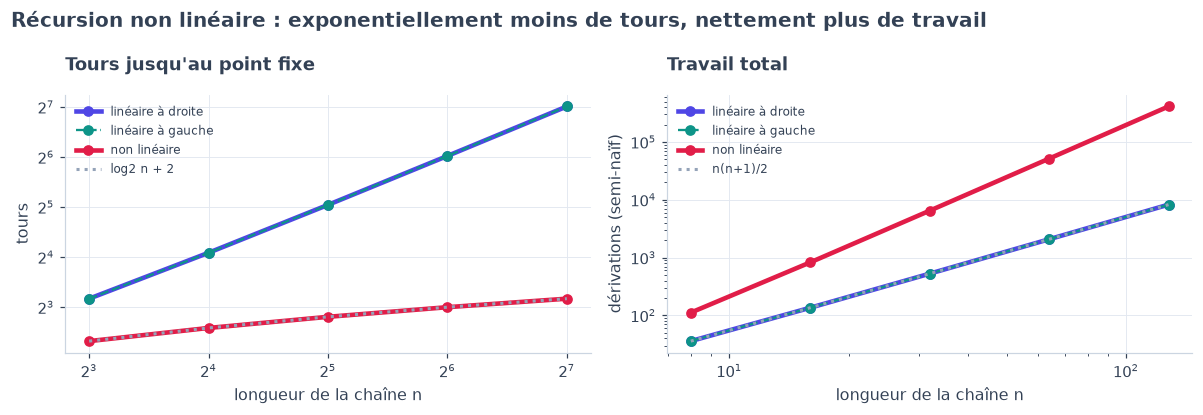

In [7]:
def chain(n, rule):
    prog = " ".join(f"edge({i}, {i + 1})." for i in range(n)) + " path(X, Y) :- edge(X, Y). " + rule
    return prog
RULES = {"linéaire à droite": "path(X, Z) :- edge(X, Y), path(Y, Z).",
         "linéaire à gauche": "path(X, Z) :- path(X, Y), edge(Y, Z).",
         "non linéaire": "path(X, Z) :- path(X, Y), path(Y, Z)."}
rows = []
for n in [8, 16, 32, 64, 128]:
    for name, r in RULES.items():
        d = dm.Datalog(chain(n, r)); s = d.evaluate("seminaive")
        assert len(d.rel["path"]) == n * (n + 1) // 2
        rows.append({"n": n, "programme": name, "tours": s["iterations"], "dérivations": s["derivations"]})
res = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, sub), col, ls in zip(res.groupby("programme", sort=False), [INDIGO, TEAL, ROSE], ["-", "--", "-"]):
    axes[0].plot(sub.n, sub.tours, marker="o", color=col, ls=ls, lw=3 if ls == "-" else 1.5, label=name)
    axes[1].plot(sub.n, sub["dérivations"], marker="o", color=col, ls=ls, lw=3 if ls == "-" else 1.5, label=name)
ns = np.array([8, 16, 32, 64, 128])
axes[0].plot(ns, np.ceil(np.log2(ns)) + 2, ls=":", color=GRAY, label="log2 n + 2")
axes[0].set_xscale("log", base=2); axes[0].set_yscale("log", base=2)
axes[0].set_xlabel("longueur de la chaîne n"); axes[0].set_ylabel("tours"); axes[0].legend(fontsize=8)
axes[0].set_title("Tours jusqu'au point fixe")
axes[1].loglog(ns, ns * (ns + 1) / 2, ls=":", color=GRAY, label="n(n+1)/2")
axes[1].set_xlabel("longueur de la chaîne n"); axes[1].set_ylabel("dérivations (semi-naïf)"); axes[1].legend(fontsize=8)
axes[1].set_title("Travail total")
finish(fig, "Récursion non linéaire : exponentiellement moins de tours, nettement plus de travail")
res.pivot(index="n", columns="programme", values=["tours", "dérivations"])

Les mesures confirment l'analyse : $n + 1$ tours et $n(n+1)/2$ dérivations pour les deux
programmes linéaires, $\log_2 n + 2$ tours pour le non linéaire, mais des dérivations qui
croissent bien plus vite (presque comme $n^3$).

> **À retenir.** La forme de la récursion fixe le nombre de tours : linéaire, un niveau
> par tour ($n$ tours) ; non linéaire, doublement ($\log_2 n$ tours) au prix de
> dérivations redondantes. On échange du calcul contre des étapes de synchronisation.